In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Skip lines starting with '#' as comments, and use the first non-comment row as header
data = pd.read_csv("/content/balance-scale.csv", comment='#', header=0)

print("first five records:")
display(data.head())
print("\nlast five records:")
display(data.tail())


first five records:


,class,left_weight,left_distance,right_weight,right_distance
0,1,1,1,1,1
1,2,1,1,1,2
2,2,1,1,1,3
3,2,1,1,1,4
4,2,1,1,1,5



last five records:


,class,left_weight,left_distance,right_weight,right_distance
620,0,5,5,5,1
621,0,5,5,5,2
622,0,5,5,5,3
623,0,5,5,5,4
624,1,5,5,5,5


### 1. Exploratory Data Analysis (EDA)
Let's visualize the distribution of classes (`class`) to understand how balanced the dataset is.

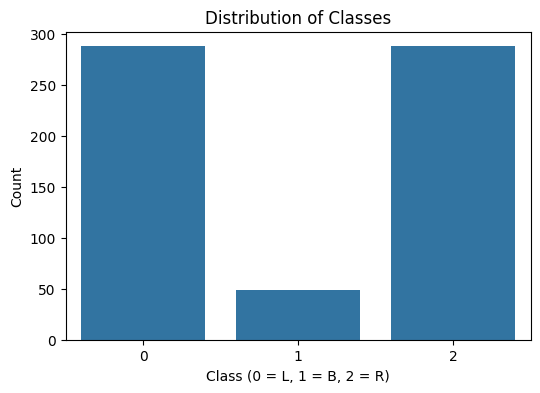

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(x='class', data=data)
plt.title('Distribution of Classes')
plt.xlabel('Class (0 = L, 1 = B, 2 = R)')
plt.ylabel('Count')
plt.show()

### 2. Prepare Data for Model Training
Let's split the dataset into independent variables (features, $X$) and the dependent target variable ($y$), followed by dividing them into training (80%) and testing (20%) datasets.

In [ ]:
# Separate features and target
X = data.drop(columns=['class'])
y = data['class']

# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 500 samples
Testing set size: 125 samples


### 3. Model Training & Evaluation
Now, we train the `GaussianNB` classifier and evaluate its performance on our test subset.

Accuracy Score: 0.9200

Classification Report:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96        58
           1       0.00      0.00      0.00        10
           2       0.92      1.00      0.96        57

    accuracy                           0.92       125
   macro avg       0.61      0.67      0.64       125
weighted avg       0.85      0.92      0.88       125



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


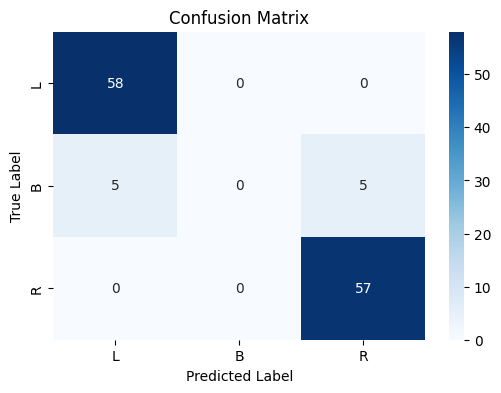

In [ ]:
# Initialize and train the model
model = GaussianNB()
model.fit(X_train, y_train)

# Make predictions on test data
y_pred = model.predict(X_test)

# Print metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['L', 'B', 'R'], yticklabels=['L', 'B', 'R'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

### Exercise 1: Address Class Imbalance using Oversampling
We will use `RandomOverSampler` from the `imblearn` library to balance our training dataset and train our Naive Bayes model again.

In [ ]:
from imblearn.over_sampling import RandomOverSampler

# Balance the training set
ros = RandomOverSampler(random_state=42)
X_train_balanced, y_train_balanced = ros.fit_resample(X_train, y_train)

print("Original class distribution in training set:")
print(y_train.value_counts())
print("\nBalanced class distribution in training set:")
print(y_train_balanced.value_counts())

# Train Naive Bayes on balanced data
model_balanced = GaussianNB()
model_balanced.fit(X_train_balanced, y_train_balanced)
y_pred_balanced = model_balanced.predict(X_test)

print(f"\nNew Accuracy: {accuracy_score(y_test, y_pred_balanced):.4f}")
print("\nNew Classification Report:")
print(classification_report(y_test, y_pred_balanced, target_names=['L', 'B', 'R']))

Original class distribution in training set:
class
2    231
0    230
1     39
Name: count, dtype: int64

Balanced class distribution in training set:
class
2    231
0    231
1    231
Name: count, dtype: int64

New Accuracy: 0.7360

New Classification Report:
              precision    recall  f1-score   support

           L       1.00      0.78      0.87        58
           B       0.22      0.90      0.35        10
           R       0.97      0.67      0.79        57

    accuracy                           0.74       125
   macro avg       0.73      0.78      0.67       125
weighted avg       0.93      0.74      0.79       125



### Exercise 2: Compare with other Classifiers (Decision Tree & Random Forest)
Since this dataset is based on logical balance scale equations, tree-based models usually perform exceptionally well here.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Initialize models
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# Train and evaluate each model
for name, clf in models.items():
    clf.fit(X_train_balanced, y_train_balanced) # using the balanced training set
    predictions = clf.predict(X_test)

    print(f"=== {name} ===")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
    print(classification_report(y_test, predictions, target_names=['L', 'B', 'R']))
    print("-" * 50)

=== Decision Tree ===
Accuracy: 0.7840
              precision    recall  f1-score   support

           L       0.85      0.88      0.86        58
           B       0.00      0.00      0.00        10
           R       0.90      0.82      0.86        57

    accuracy                           0.78       125
   macro avg       0.58      0.57      0.58       125
weighted avg       0.81      0.78      0.79       125

--------------------------------------------------
=== Random Forest ===
Accuracy: 0.7840
              precision    recall  f1-score   support

           L       0.85      0.90      0.87        58
           B       0.00      0.00      0.00        10
           R       0.94      0.81      0.87        57

    accuracy                           0.78       125
   macro avg       0.60      0.57      0.58       125
weighted avg       0.82      0.78      0.80       125

--------------------------------------------------


### Exercise 3: Feature Engineering (Unlocking 100% Accuracy)
Let's calculate the theoretical torque (force) acting on each side of the scale and use those as new features for our Decision Tree.

In [ ]:
# 1. Feature Engineering: Calculate the actual product of weight and distance
data_engineered = data.copy()
data_engineered['left_torque'] = data_engineered['left_weight'] * data_engineered['left_distance']
data_engineered['right_torque'] = data_engineered['right_weight'] * data_engineered['right_distance']

# 2. Separate into features and target using our newly engineered features
X_eng = data_engineered[['left_torque', 'right_torque']]
y_eng = data_engineered['class']

# 3. Train/Test split
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(X_eng, y_eng, test_size=0.2, random_state=42, stratify=y_eng)

# 4. Train a Decision Tree Classifier on the engineered features
dt_eng = DecisionTreeClassifier(random_state=42)
dt_eng.fit(X_train_eng, y_train_eng)
predictions_eng = dt_eng.predict(X_test_eng)

# 5. Evaluate the results
print(f"Engineered Model Accuracy: {accuracy_score(y_test_eng, predictions_eng):.4f}\n")
print("Classification Report with Engineered Features:")
print(classification_report(y_test_eng, predictions_eng, target_names=['L', 'B', 'R']))

Engineered Model Accuracy: 1.0000

Classification Report with Engineered Features:
              precision    recall  f1-score   support

           L       1.00      1.00      1.00        58
           B       1.00      1.00      1.00        10
           R       1.00      1.00      1.00        57

    accuracy                           1.00       125
   macro avg       1.00      1.00      1.00       125
weighted avg       1.00      1.00      1.00       125

